<a href="https://colab.research.google.com/github/rahul-kothari/transparent-obj-detection/blob/main/VGG19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```
COMP 592 - Transparent Object Detection
Rahul Kothari
Student ID: 201316606
University of Liverpool, 2021
```
VGG-19 Transfer Learning

# Instructions
**You are required to mount this to your google drive.**
* The data must be stored in a sub-directory called "data" in the format:
```
MAIN DIRECTORY
  | Data
     | train
        | Glass(24).jpg
        | ...
        | region_data_train.json
     | val
        | Glass(41).jpg
        | ...
        | region_data_val.json
  | logs
     | mask-rcnn
     | vgg
```
* The logs, model will be stored at your specified location in your google drive!

# Configuration 

In [ ]:
import os
import json
import numpy as np
import cv2
from datetime import datetime
from tensorflow.keras.applications.vgg19 import VGG19, preprocess_input
from tensorflow.keras.layers import Flatten, Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

%matplotlib inline

In [ ]:
# Some constants:
ROOT_DIR = os.getcwd() # /content folder in gdrive.
user_specified_location = input("Enter your google drive directory where data is hosted and where model will be stored. e.g. \"Colab Notebooks/COMP592_Transaprent_Obj_Detection\":") 
GDRIVE_FOLDER_PATH = os.path.join(ROOT_DIR, "drive/MyDrive", user_specified_location")
DATASET_DIR = os.path.join(GDRIVE_FOLDER_PATH, "data")

# Directory to save logs and trained model
MODEL_DIR = os.path.join(GDRIVE_FOLDER_PATH, "logs", "vgg")

# Constantls for the VGG model
inputShape = (224, 224)
INIT_LR = 1e-4
NUM_EPOCHS = 25
BATCH_SIZE = 32

# Data Preprocessing
1. For all images (train, val), convert polygon to rectangles (for bbox regression - since polygon bbox is very hard, but rectangle is easy)

2. Store the rectangle coordinates as "Y"

3. Convert all images into VGG style. Store them as "X"

## Convert polygon to rectangle coordinates:


In [ ]:
from scipy.spatial import ConvexHull
# https://gis.stackexchange.com/questions/22895/finding-minimum-area-rectangle-for-given-points/169633#169633

def minimum_bounding_rectangle(points):
    """
    Find the smallest bounding rectangle for a set of points.
    Returns a set of points representing the corners of the bounding box.

    :param points: an nx2 matrix of coordinates
    :rval: an nx2 matrix of coordinates
    """
    from scipy.ndimage.interpolation import rotate
    pi2 = np.pi/2.

    # get the convex hull for the points
    hull_points = points[ConvexHull(points).vertices]

    # calculate edge angles
    edges = np.zeros((len(hull_points)-1, 2))
    edges = hull_points[1:] - hull_points[:-1]

    angles = np.zeros((len(edges)))
    angles = np.arctan2(edges[:, 1], edges[:, 0])

    angles = np.abs(np.mod(angles, pi2))
    angles = np.unique(angles)

    # find rotation matrices
    # XXX both work
    rotations = np.vstack([
        np.cos(angles),
        np.cos(angles-pi2),
        np.cos(angles+pi2),
        np.cos(angles)]).T
#     rotations = np.vstack([
#         np.cos(angles),
#         -np.sin(angles),
#         np.sin(angles),
#         np.cos(angles)]).T
    rotations = rotations.reshape((-1, 2, 2))

    # apply rotations to the hull
    rot_points = np.dot(rotations, hull_points.T)

    # find the bounding points
    min_x = np.nanmin(rot_points[:, 0], axis=1)
    max_x = np.nanmax(rot_points[:, 0], axis=1)
    min_y = np.nanmin(rot_points[:, 1], axis=1)
    max_y = np.nanmax(rot_points[:, 1], axis=1)

    # find the box with the best area
    areas = (max_x - min_x) * (max_y - min_y)
    best_idx = np.argmin(areas)

    # return the best box
    x1 = max_x[best_idx]
    x2 = min_x[best_idx]
    y1 = max_y[best_idx]
    y2 = min_y[best_idx]
    r = rotations[best_idx]

    rval = np.zeros((4, 2))
    rval[0] = np.dot([x1, y2], r)
    rval[1] = np.dot([x2, y2], r)
    rval[2] = np.dot([x2, y1], r)
    rval[3] = np.dot([x1, y1], r)

    return np.int32(rval)

### **DON'T TOUCH. - Useful output for thesis on how polygon to rectangle conversion worked!**

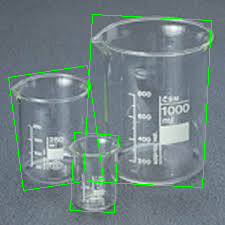

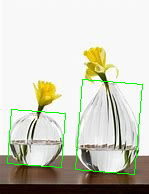

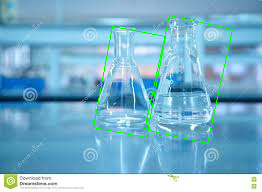

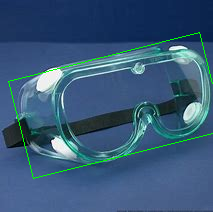

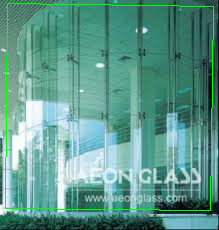

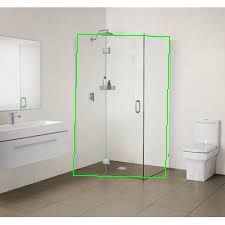

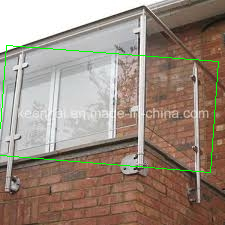

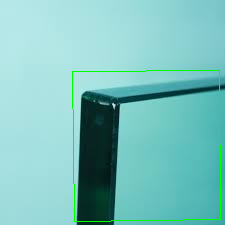

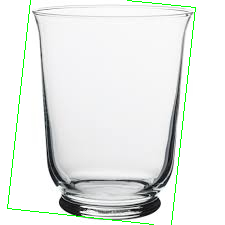

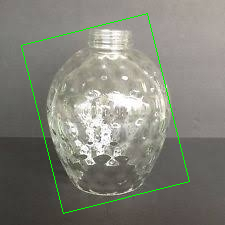

In [ ]:
"""
Script to test conversion of polygon annots to rectangle bbox for 10 original image (not 224*224)
"""
annotation_file_path = os.path.join("/content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/data/val/region_data_val.json")
annotations = json.load(open(annotation_file_path))
if type(annotations) == dict:
  annotations = list(annotations.values())
elif type(annotations) != list:
  raise TypeError("annotations must be of type dict or list")
# else -> type == list.

for a in annotations[0:10]: 
  image = cv2.imread("/content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/data/val/"+a["filename"])
  polygons = [r['shape_attributes'] for r in a['regions'].values()]
  for p in polygons:
    # for each polygon, get x,y annotation points. Convert to rectangle bbox and plot to check.
    points = np.vstack((p['all_points_x'], p['all_points_y'])).T
    rval = minimum_bounding_rectangle(points)
    cv2.polylines(image, [rval], True, (0,255,0))
  cv2_imshow(image)

In [ ]:
"""
Script to test conversion of polygon annots to rectangle bbox for scaled image (224*224 instead of original image)
"""
annotation_file_path = os.path.join("/content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/data/val/region_data_val.json")
annotations = json.load(open(annotation_file_path))
if type(annotations) == dict:
  annotations = list(annotations.values())
elif type(annotations) != list:
  raise TypeError("annotations must be of type dict or list")
# else -> type == list.

for a in annotations[0:10]: 
  image_path = "/content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/data/val/"+a["filename"]
  _, image, h_old, w_old = preprocess_image(image_path)
  polygons = [r['shape_attributes'] for r in a['regions'].values()]

  # Find ratio - unitary method to scale all points to new image of size 224*224
  h_new, w_new = inputShape[:2]
  h_ratio, w_ratio = h_new/h_old, w_new/w_old
  ratio = np.array([h_ratio, w_ratio])
  
  for p in polygons:
    # for each polygon, get x,y annotation points. Scale to 224*224.
    # Then, convert to rectangle bbox and plot to check.
    points = np.vstack((p['all_points_x'], p['all_points_y'])).T
    points = points * ratio
    rval = minimum_bounding_rectangle(points)
    cv2.polylines(image, [rval], True, (0,255,0))
  cv2_imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

## Load and prepare Data

In [ ]:
def preprocess_image(path):
  """
  helper function to load image and preprocess it for vgg
  :param path - of the image
  :returns x - preprocessed image
  :returns img - resized image
  :returns scale_ratio = [h_new/original_height, w_new/original_width], where h_new, w_new = 224,224.
  """

  img = cv2.imread(path)
  original_height, original_width = img.shape[:2]
  img = cv2.resize(img, inputShape)  

  # Find ratio for scaling indices to new image of size 224*224 (Unitary method)
  h_new, w_new = inputShape[:2]
  h_ratio, w_ratio = h_new/original_height, w_new/original_width
  scale_ratio = np.array([h_ratio, w_ratio])

  # Change img size to (1, inputShape[0], inputShape[1], 3). 
  # Without this model.predict will throw error
  x = np.expand_dims(img, axis=0)
  x = preprocess_input(x)

  return x, img, scale_ratio

def preprocess_images(annotations, dataset_dir):
  annotations = [a for a in annotations if a['regions']]
  num_images = len(annotations)
  data = np.zeros((num_images, 224, 224, 3))
  targets = np.zeros((num_images, 8)) # 4 xy coods flattened.
  for i in range(0, num_images):
    a = annotations[i]
    # Get the x, y coordinates of points of the polygons that make up
    # the outline of each object instance. 
    # The if condition is needed to support VIA versions 1.x and 2.x.
    if type(a['regions']) is dict:
        polygons = [r['shape_attributes'] for r in a['regions'].values()]
    else:
        polygons = [r['shape_attributes'] for r in a['regions']] 
    
    # Get image. Get preprocessed image. Create rectangle boundary box coordinates for the scaled image.
    image_path = os.path.join(dataset_dir, a['filename'])
    x, img, ratio = preprocess_image(image_path)
    boundaryBoxCoods = np.zeros((4,2))
    polygon = polygons[0] #single image dataset, so all polygons are the same.
    # get x,y annotation points. Scale to 224*224.
    # Then, convert to rectangle bbox and plot to check.
    points = np.vstack((polygon['all_points_x'], polygon['all_points_y'])).T
    points = points * ratio
    boundaryBoxCoods = minimum_bounding_rectangle(points)
    
    data[i] = x
    targets[i] = boundaryBoxCoods.flatten()
  return data, targets

In [ ]:
def loadAndPrepareData(mode):
  """Load annotations for train/val dataset. Convert them to rectangle. Preprocess image VGG19 style.
  :returns data: (n,224,224,3) where n = number of images
  :returns targets: (n,4,2) - rectangle box coordinates for each rectangle
  """

  # Train or validation dataset?
  assert mode in ["train", "val"]
  dataset_dir = os.path.join(DATASET_DIR, mode)
  annotation_file_path = os.path.join(dataset_dir, "region_data_"+mode+"_single_imgs.json")
  annotations = json.load(open(annotation_file_path))
  if type(annotations) == dict:
    annotations = list(annotations.values())
  elif type(annotations) != list:
    raise TypeError("annotations must be of type dict or list")
  # else -> type == list.

  return preprocess_images(annotations, dataset_dir)

# Training dataset
data, targets = loadAndPrepareData("train")
print("Train: data.shape shape: {} \t targets.shape: {}".format(data.shape, targets.shape))

# validation dataset
data_val, targets_val = loadAndPrepareData("val")
print("Val: data.shape shape: {} \targets.shape: {}".format(data_val.shape, targets_val.shape))

Train: data.shape shape: (242, 224, 224, 3) 	 targets.shape: (242, 8)
Val: data.shape shape: (89, 224, 224, 3) 	argets.shape: (89, 8)


# 2. Train Model

In [ ]:
model = VGG19(include_top=False, input_tensor=Input(shape=(224, 224, 3)))
# freeze all VGG layers 
model.trainable = False
# flatten the max-pooling output of VGG
flatten = model.output
flatten = Flatten()(flatten)
# construct a fully-connected layer header to output the predicted
# bounding box coordinates
bboxHead = Dense(128, activation="relu")(flatten)
bboxHead = Dense(64, activation="relu")(bboxHead)
bboxHead = Dense(32, activation="relu")(bboxHead)
bboxHead = Dense(8, activation="sigmoid")(bboxHead)
# construct the model we will fine-tune for bounding box regression
model = Model(inputs=model.input, outputs=bboxHead)

opt = Adam(lr=INIT_LR)
model.compile(loss="mse", optimizer=opt)

print(model.summary())

80142336/80134624 [==============================] - 1s 0us/step
Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
block1_conv1 (Conv2D)        (None, 224, 224, 64)      1792      
_________________________________________________________________
block1_conv2 (Conv2D)        (None, 224, 224, 64)      36928     
_________________________________________________________________
block1_pool (MaxPooling2D)   (None, 112, 112, 64)      0         
_________________________________________________________________
block2_conv1 (Conv2D)        (None, 112, 112, 128)     73856     
_________________________________________________________________
block2_conv2 (Conv2D)        (None, 112, 112, 128)     147584    
______________________________________________________________

In [ ]:
print("[INFO] training bounding box regressor...")
H = model.fit(data, targets, 
              validation_data=(data_val, targets_val),
	            batch_size=BATCH_SIZE,
              epochs=250,
              verbose=1)

[INFO] training bounding box regressor...
Epoch 1/250
8/8 [==============================] - 49s 1s/step - loss: 22491.0243 - val_loss: 24230.2969
Epoch 2/250
8/8 [==============================] - 2s 201ms/step - loss: 22749.5924 - val_loss: 24228.2305
Epoch 3/250
8/8 [==============================] - 2s 203ms/step - loss: 22338.4520 - val_loss: 24228.1738
Epoch 4/250
8/8 [==============================] - 2s 204ms/step - loss: 22462.2391 - val_loss: 24228.1719
Epoch 5/250
8/8 [==============================] - 2s 202ms/step - loss: 22379.7348 - val_loss: 24228.1719
Epoch 6/250
8/8 [==============================] - 2s 203ms/step - loss: 22812.6552 - val_loss: 24228.1680
Epoch 7/250
8/8 [==============================] - 2s 206ms/step - loss: 22221.1374 - val_loss: 24228.1680
Epoch 8/250
8/8 [==============================] - 2s 206ms/step - loss: 22381.6951 - val_loss: 24228.1680
Epoch 9/250
8/8 [==============================] - 2s 203ms/step - loss: 22342.0512 - val_loss: 24228.16

In [ ]:
print("[INFO] saving object detector model...")
model_path = os.path.join(MODEL_DIR, "detector"+datetime.now().strftime("%Y%m%dT%H%M") + ".h5")
model.save(model_path, save_format="h5")

[INFO] saving object detector model...


# 3. Evaluation of Model

**ALSO DO https://medium.com/@nirbarazida/transfer-learning-of-cnn-model-using-google-colab-part-ii-da4eff2d8daf**

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/COMP592_Transaprent_Obj_Detection/logs/vgg/detector20210414T1433.h5"
from tensorflow.keras.models import load_model 
model = load_model(MODEL_PATH)

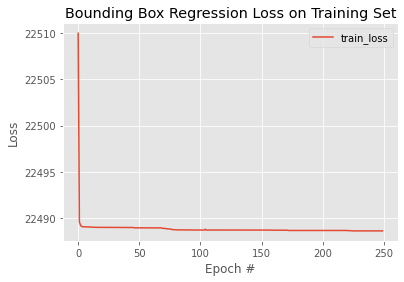

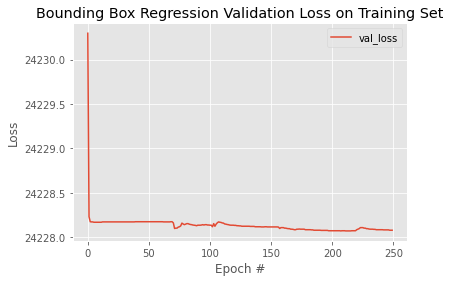

In [ ]:
# plot the model training history
N = 250
plt.plot(np.arange(0, N), H.history["loss"], label="train_loss")
#axs[1].plot(np.arange(0, N), H.history["val_loss"], label="val_loss")
plt.title("Bounding Box Regression Loss on Training Set")
plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.show()

N = 250
plt.plot(np.arange(0, N), H.history["val_loss"], label="val_loss")
plt.title("Bounding Box Regression Validation Loss on Training Set")
plt.xlabel("Epoch #")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.show()

In [ ]:
def evaluateImage(image_path, model):
  """Load an image, preprocess it vgg style. Get bbox prediction. And plot the bbox on the image! """
  img = cv2.imread(image_path)
  original_height, original_width = img.shape[:2]
  img = cv2.resize(img, inputShape)  

  # Change img size to (1, inputShape[0], inputShape[1], 3). 
  # Without this model.predict will throw error
  x = np.expand_dims(img, axis=0)
  x = preprocess_input(x)

  # x, img, scale = preprocess_image(image_path)
  preds = model.predict(x)[0]
  # preds is a 1D array of 8 points. Resize to 4 x,y points.
  preds.resize(4,2)
  preds = preds.astype(int)
  print(preds)
  cv2.polylines(img, [preds], True, (0,255,0))
  cv2_imshow(img)

[[1 1]
 [1 0]
 [0 1]
 [1 1]]


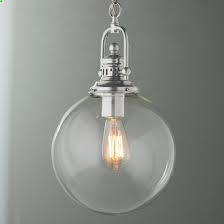

In [ ]:
image_path = os.path.join(DATASET_DIR, "val/Glass60.jpg")
evaluateImage(image_path, model)